In [1]:
# 导入与全局配置
import os
import random

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

from net_4 import CatsDogsModel
from data_processor_3 import _build_transforms

# 中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC']
plt.rcParams['axes.unicode_minus'] = False

# 在 Jupyter 中以内嵌方式显示图片
%matplotlib inline

import yaml
with open("config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.load(f, Loader=yaml.FullLoader)
TEST_ROOT = cfg["data_root"]
MODEL_PATH = "saved_model/best_model.pth"

# net_4.CatsDogsModel.features 中的索引
CONV1_IDX = 0        # 第一层卷积  Conv2d(3, 96, k=11, s=4, p=2)
CONV_LAST_IDX = 14   # 最后一层卷积 Conv2d(384, 256, k=3, s=1, p=1)

In [2]:
# 加载模型（有训练权重就用，没有就用随机初始化）
def load_model(device):
    model = CatsDogsModel()
    if os.path.exists(MODEL_PATH):
        state = torch.load(MODEL_PATH, map_location=device)
        model.load_state_dict(state)
        print(f"[模型] 已加载训练权重: {MODEL_PATH}")
    else:
        print(f"[模型] 未找到 {MODEL_PATH}，使用随机初始化权重")
    model.eval()
    return model.to(device)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[设备] {device}")
model = load_model(device)

[设备] cuda
[模型] 已加载训练权重: saved_model/best_model.pth


In [3]:
# 从 test1 里挑选若干张图片
def collect_test_images(root, n_per_class=2, seed=42):
    random.seed(seed)
    exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

    def list_imgs(d):
        if not os.path.isdir(d):
            return []
        return [os.path.join(d, f) for f in os.listdir(d)
                if f.lower().endswith(exts)]

    sub_cat = list_imgs(os.path.join(root, "cat"))
    sub_dog = list_imgs(os.path.join(root, "dog"))

    samples = []

    # 情况 A：cat/ 和 dog/ 里都有图片
    if len(sub_cat) > 0 and len(sub_dog) > 0:
        for cls, files in [("cat", sub_cat), ("dog", sub_dog)]:
            for f in random.sample(files, min(n_per_class, len(files))):
                samples.append((f, cls))

    # 情况 B / C：子目录为空 → 扁平扫描 root
    else:
        flat = list_imgs(root)
        if not flat:
            return []
        picked = random.sample(flat, min(n_per_class * 2, len(flat)))
        for f in picked:
            # 文件名以 cat/dog 开头的话，顺带把标签也推出来（仅用于展示）
            base = os.path.basename(f).lower()
            label = "cat" if base.startswith("cat") else \
                    "dog" if base.startswith("dog") else "unknown"
            samples.append((f, label))

    return samples

samples = collect_test_images(TEST_ROOT, n_per_class=2, seed=42)
print(f"共选中 {len(samples)} 张测试图片：")
for p, lab in samples:
    print(f"  - {p}  [{lab}]")

共选中 4 张测试图片：
  - ./cats_and_dogs/test1\8177.jpg  [unknown]
  - ./cats_and_dogs/test1\1164.jpg  [unknown]
  - ./cats_and_dogs/test1\10366.jpg  [unknown]
  - ./cats_and_dogs/test1\9683.jpg  [unknown]


In [4]:
# 用 forward hook 抓取 conv1 / conv_last 的输出
def _extract_features(model, x, layer_indices):
    #返回 {idx: tensor[N, C, H, W]}
    acts = {}
    handles = []

    def make_hook(idx):
        def hook(module, inp, out):
            acts[idx] = out.detach().cpu()
        return hook

    for idx in layer_indices:
        handles.append(model.features[idx].register_forward_hook(make_hook(idx)))

    with torch.no_grad():
        model(x)

    for h in handles:
        h.remove()
    return acts

In [5]:
# 可视化单张图片
def visualize_image(model, img_path, label, transform, device,
                    n_channels=8, seed=0):
    img_pil = Image.open(img_path).convert("RGB")
    x = transform(img_pil).unsqueeze(0).to(device)

    acts = _extract_features(model, x, [CONV1_IDX, CONV_LAST_IDX])
    c1 = acts[CONV1_IDX][0]      # [96, 55, 55]
    cL = acts[CONV_LAST_IDX][0]  # [256, 13, 13]

    rng = random.Random(seed)
    ch1 = rng.sample(range(c1.shape[0]), n_channels - 1)
    chL = rng.sample(range(cL.shape[0]), n_channels)

    fig = plt.figure(figsize=(2.2 * n_channels, 5.4))
    gs = fig.add_gridspec(2, n_channels, hspace=0.22, wspace=0.05)

    # 上排左1：原图
    ax = fig.add_subplot(gs[0, 0])
    ax.imshow(img_pil)
    ax.set_title(f"原图  [{label}]", fontsize=10)
    ax.axis("off")

    # 上排其余：conv1 通道
    for i, ch in enumerate(ch1):
        ax = fig.add_subplot(gs[0, i + 1])
        ax.imshow(c1[ch].numpy(), cmap="viridis", interpolation="nearest")
        ax.set_title(f"conv1 ch{ch}", fontsize=9)
        ax.axis("off")

    # 下排：conv_last 通道
    for i, ch in enumerate(chL):
        ax = fig.add_subplot(gs[1, i])
        ax.imshow(cL[ch].numpy(), cmap="viridis", interpolation="nearest")
        ax.set_title(f"conv_last ch{ch}", fontsize=9)
        ax.axis("off")

    fig.suptitle(
        f"{os.path.basename(img_path)}  |  上排: conv1 通道,  "
        f"下排: conv_last 通道",
        fontsize=12,
    )
    plt.tight_layout()
    plt.show()


>>> (1/4) ./cats_and_dogs/test1\8177.jpg


C:\Users\34854\AppData\Local\Temp\ipykernel_13044\2225182387.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


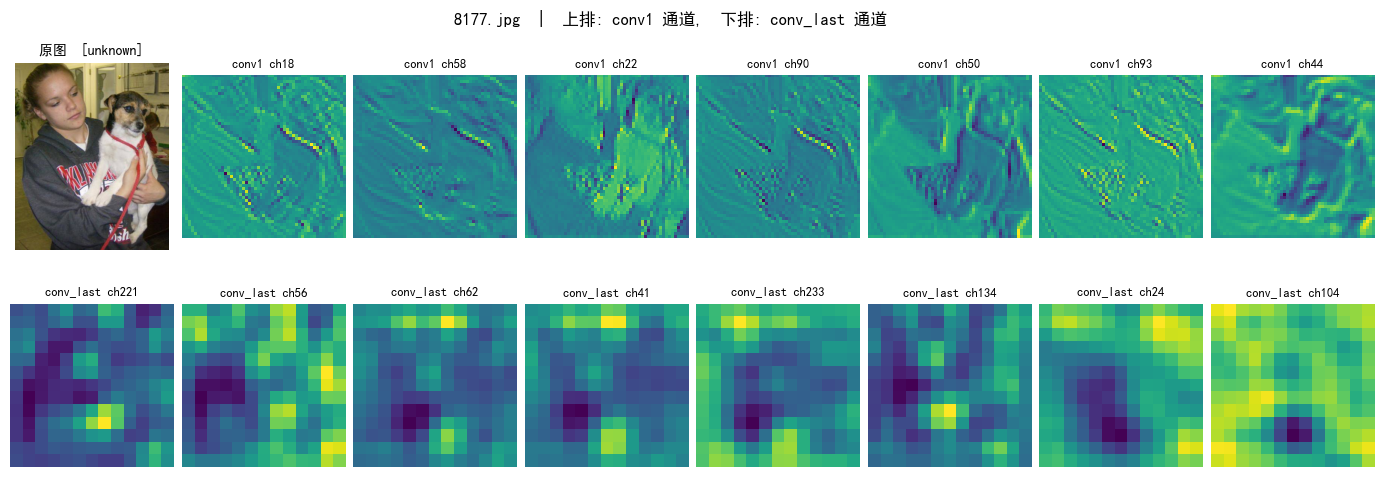


>>> (2/4) ./cats_and_dogs/test1\1164.jpg


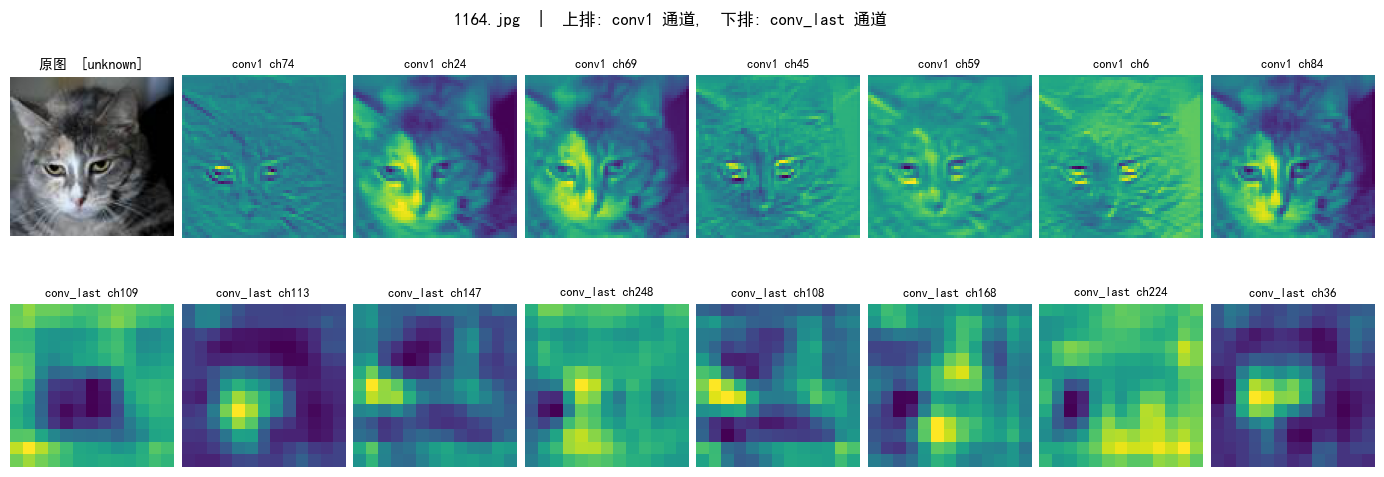


>>> (3/4) ./cats_and_dogs/test1\10366.jpg


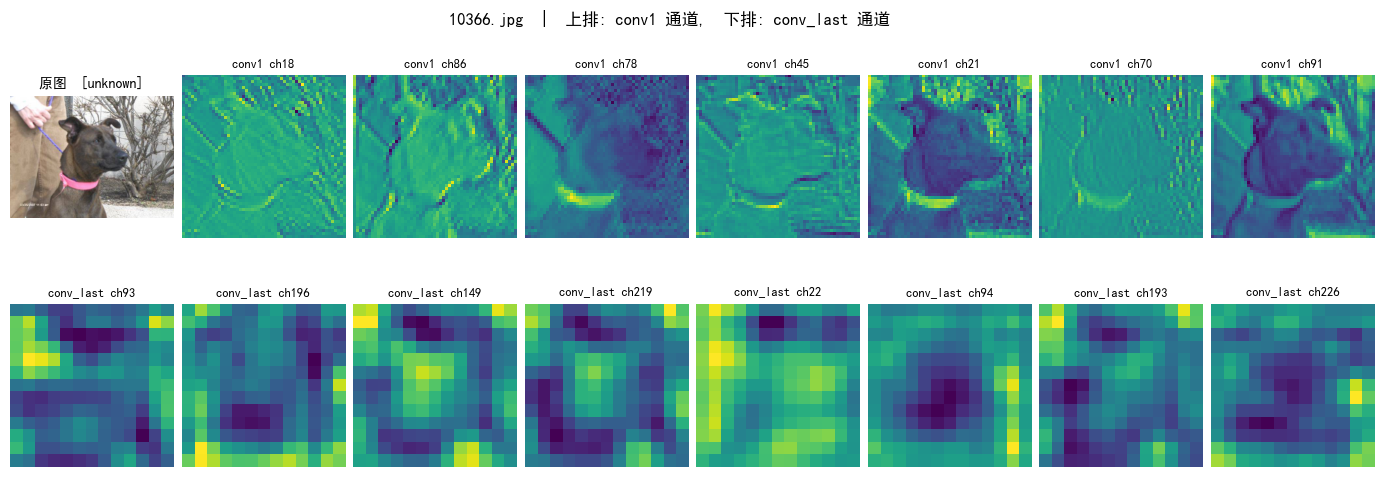


>>> (4/4) ./cats_and_dogs/test1\9683.jpg


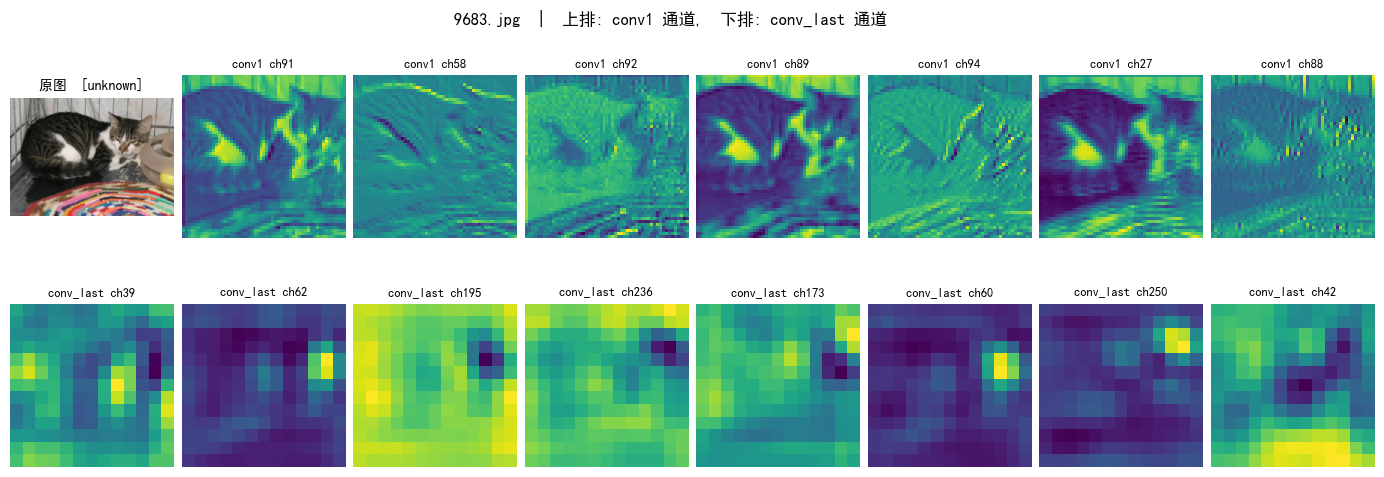

In [6]:
# 对选中的图片逐张可视化
_, eval_tf = _build_transforms()

for k, (path, label) in enumerate(samples):
    print(f"\n>>> ({k + 1}/{len(samples)}) {path}")
    visualize_image(model, path, label, eval_tf, device,
                    n_channels=8, seed=100 + k)

In [7]:
# 结果解读，此部分由AI根据文件生成
print("=" * 70)
print("如何看这些特征图：")
print("-" * 70)
print("conv1（上排，96 通道，[55,55]，每个像素≈原图 4 像素）：")
print("  · 属于低级视觉特征，通道间差异非常大；")
print("  · 常见几类：某些通道在竖直/水平/斜向边缘上呈亮条带（边缘检测器）；")
print("    某些通道对特定颜色斑块（红、蓝、绿）整体响应；")
print("    某些通道对毛发、草地、文字类高频纹理区域亮；")
print("  · 单通道分辨率高但语义弱，只“看得到”局部像素模式。")
print()
print("conv_last（下排，256 通道，[13,13]，每个位置感受野≈原图 1/7）：")
print("  · 分辨率低、形态模糊，但通道之间激活区域差异极大；")
print("  · 已是从“边缘/颜色”抽象出来的部件级、语义级响应；")
print("  · 常见：部分通道只在眼睛、耳朵、鼻子附近亮；")
print("    部分通道只对背景（草地、天空、沙发）亮；")
print("    部分通道几乎不激活，说明该特征在当前图片上不存在。")
print()
print("结论：")
print("  同一张图片在不同通道上产生的是“多视角”响应：")
print("  底层通道看颜色与边缘，深层通道看部位与语义；")
print("  网络靠多个通道的联合激活共同编码这张图片。")
print("=" * 70)

如何看这些特征图：
----------------------------------------------------------------------
conv1（上排，96 通道，[55,55]，每个像素≈原图 4 像素）：
  · 属于低级视觉特征，通道间差异非常大；
  · 常见几类：某些通道在竖直/水平/斜向边缘上呈亮条带（边缘检测器）；
    某些通道对特定颜色斑块（红、蓝、绿）整体响应；
    某些通道对毛发、草地、文字类高频纹理区域亮；
  · 单通道分辨率高但语义弱，只“看得到”局部像素模式。

conv_last（下排，256 通道，[13,13]，每个位置感受野≈原图 1/7）：
  · 分辨率低、形态模糊，但通道之间激活区域差异极大；
  · 已是从“边缘/颜色”抽象出来的部件级、语义级响应；
  · 常见：部分通道只在眼睛、耳朵、鼻子附近亮；
    部分通道只对背景（草地、天空、沙发）亮；
    部分通道几乎不激活，说明该特征在当前图片上不存在。

结论：
  同一张图片在不同通道上产生的是“多视角”响应：
  底层通道看颜色与边缘，深层通道看部位与语义；
  网络靠多个通道的联合激活共同编码这张图片。
